# PatchBridgeNet - Train, Evaluate and Export (Colab)

Run the cells **from top to bottom, one at a time** (GPU runtime recommended: Runtime > Change runtime type > GPU).

What this notebook does:
1. Rebuilds the exact PatchBridgeNet pipeline (patches + MobileNetV2/DarkNet53/DenseNet201 + INCA + Chi2 + quadratic SVM).
2. Runs the leak-free 10-fold cross-validation and **prints the accuracy of both models and the difference from the paper**.
3. Calibrates the SVM scores so that the GUI can show **percentages** (binary: Diseased %, 7-class: % per disease).
4. Fits the final models on the full dataset and saves them as **pickle files** (plain NumPy dictionaries, no scikit-learn objects).
5. Tests the saved files through the same code path the GUI uses (live image -> features -> prediction -> Grad-CAM).
6. Zips everything for download. Then use `app.py` locally.

If the original notebook was already run with the same settings, its feature cache (`*_views*.npy`) and INCA cache in Google Drive are reused, so this notebook is much faster.

## Cell 1: install packages

In [1]:
!pip install timm -q
import sklearn, torch, torchvision, timm
print("scikit-learn", sklearn.__version__)
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| timm", timm.__version__)

scikit-learn 1.6.1
torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | timm 1.0.30


## Cell 2: mount Google Drive

In [2]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


## Cell 3: copy and unzip the dataset

In [3]:
!cp "/content/drive/MyDrive/Minor project/OCTDL.zip" /content/
!unzip -q -o /content/OCTDL.zip -d /content/data/
!cp "/content/drive/MyDrive/Minor project/OCTDL_labels.csv" /content/data/

## Cell 4: write `pbn_core.py` (shared pipeline, also used by the GUI)

In [ ]:
%%writefile pbn_core.py
"""
pbn_core.py -- PatchBridgeNet shared pipeline (used by the Colab notebook AND the local Streamlit app)

Pipeline (identical to the training notebook):
    RGB image -> resize 224x224 -> ImageNet normalize
    -> original + 4 vertical patches (224x56 -> resized to 224x224)
    -> MobileNetV2 / DarkNet53 / DenseNet201 (GAP + FC features)
    -> sum of the 5 views (flip TTA: each view = (normal + flipped) / 2)
    -> per-model INCA (MinMax + selected indices) -> concatenate
    -> Chi2 indices -> StandardScaler -> quadratic SVM (one-vs-one)

The trained classifier is stored as a plain dictionary of NumPy arrays (no scikit-learn objects),
so the pickle files load on any machine regardless of the scikit-learn version.

Also provided here:
    * calibrated probabilities (percentages) computed from SVM decision values
    * Grad-CAM through the full pipeline (CNN feature maps -> INCA -> Chi2 -> SVM)
"""
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as TF
import torchvision.models as models
import torchvision.transforms as transforms
import timm
from PIL import Image

IMAGE_SIZE = 224
N_PATCHES = 4

CLASS7_NAMES = ["AMD", "DME", "ERM", "NO", "RAO", "RVO", "VID"]
CLASS7_FULL = {
    "AMD": "Age-related Macular Degeneration",
    "DME": "Diabetic Macular Edema",
    "ERM": "Epiretinal Membrane",
    "NO": "Normal",
    "RAO": "Retinal Artery Occlusion",
    "RVO": "Retinal Vein Occlusion",
    "VID": "Vitreomacular Interface Disease",
}
CLASS2_NAMES = ["Normal", "Diseased"]  # 0 = Normal, 1 = Diseased
MODEL_ORDER = ["mobilenetv2", "darknet53", "densenet201"]


# =============================================================================
# Preprocessing and patches
# =============================================================================
def get_transform(resize_mode="bilinear"):
    interp = (transforms.InterpolationMode.BICUBIC if resize_mode == "bicubic"
              else transforms.InterpolationMode.BILINEAR)
    return transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=interp),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])


def load_image(path):
    return Image.open(path).convert("RGB")


def make_patches(img_tensor, n_patches=N_PATCHES):
    width = img_tensor.shape[-1]
    patch_w = width // n_patches
    return [img_tensor[:, :, i * patch_w:(i + 1) * patch_w] for i in range(n_patches)]


def resize_patch(patch_tensor, resize_mode="bilinear"):
    p = patch_tensor.unsqueeze(0)
    mode = "bicubic" if resize_mode == "bicubic" else "bilinear"
    p = nn.functional.interpolate(p, size=(224, 224), mode=mode, align_corners=False)
    return p.squeeze(0)


def build_views(pil_img, resize_mode="bilinear"):
    """Return a (5, 3, 224, 224) tensor: [original, patch1, patch2, patch3, patch4]."""
    tensor = get_transform(resize_mode)(pil_img.convert("RGB"))
    patches = [resize_patch(p, resize_mode) for p in make_patches(tensor)]
    return torch.stack([tensor] + patches)


# =============================================================================
# Feature extractor (GAP + FC)
# =============================================================================
class FeatureExtractor(nn.Module):
    """
    mobilenetv2 -> GAP=1280, FC=1000
    darknet53   -> GAP=1024, FC=1000  (timm)
    densenet201 -> GAP=1920, FC=1000
    pretrained=False is used only when a saved state_dict is loaded afterwards (offline use).
    """

    def __init__(self, model_name, pretrained=True):
        super().__init__()
        self.model_name = model_name

        if model_name == "mobilenetv2":
            base = models.mobilenet_v2(
                weights=models.MobileNet_V2_Weights.IMAGENET1K_V1 if pretrained else None)
            self.features = base.features
            self.gap = nn.AdaptiveAvgPool2d((1, 1))
            self.fc = base.classifier
        elif model_name == "darknet53":
            self.backbone = timm.create_model("darknet53", pretrained=pretrained)
            self.gap = nn.AdaptiveAvgPool2d((1, 1))
        elif model_name == "densenet201":
            base = models.densenet201(
                weights=models.DenseNet201_Weights.IMAGENET1K_V1 if pretrained else None)
            self.features = base.features
            self.fc_layer = base.classifier
        else:
            raise ValueError(model_name)

        self.eval()
        for p in self.parameters():
            p.requires_grad = False

    def feature_map(self, x):
        """Last convolutional feature map (used by Grad-CAM)."""
        if self.model_name == "darknet53":
            return self.backbone.forward_features(x)
        return self.features(x)

    def head(self, fm):
        """GAP + FC features computed from a feature map -> (B, D) tensor."""
        b = fm.size(0)
        if self.model_name == "mobilenetv2":
            gap_feat = self.gap(fm).reshape(b, -1)
            fc_feat = self.fc(gap_feat)
        elif self.model_name == "darknet53":
            gap_feat = self.gap(fm).reshape(b, -1)
            fc_feat = self.backbone.forward_head(fm)
        else:  # densenet201
            g = nn.functional.relu(fm, inplace=False)
            g = nn.functional.adaptive_avg_pool2d(g, (1, 1))
            gap_feat = g.reshape(b, -1)
            fc_feat = self.fc_layer(gap_feat)
        return torch.cat([gap_feat, fc_feat], dim=1)

    def forward(self, x):
        return self.head(self.feature_map(x)).cpu().numpy()


def load_extractors(device, weights_path=None):
    """Load the three CNNs. If weights_path exists the saved weights are used (offline),
    otherwise the ImageNet pretrained weights are downloaded."""
    state = None
    if weights_path and os.path.exists(weights_path):
        state = torch.load(weights_path, map_location="cpu", weights_only=True)
    extractors = {}
    for name in MODEL_ORDER:
        ext = FeatureExtractor(name, pretrained=(state is None))
        if state is not None:
            ext.load_state_dict(state[name])
        extractors[name] = ext.to(device).eval()
    return extractors


def extract_image_features(pil_img, extractors, device, resize_mode="bilinear", use_flip_tta=True):
    """
    Features of ONE image, identical to one row of the training feature matrices.
    Returns [F_mobilenet (1, 2280), F_darknet (1, 2024), F_densenet (1, 2920)].
    """
    batch = build_views(pil_img, resize_mode)
    feats = []
    for name in MODEL_ORDER:
        ext = extractors[name]
        with torch.no_grad():
            v = ext(batch.to(device)).astype(np.float32)
            if use_flip_tta:
                vf = ext(torch.flip(batch, dims=[3]).to(device)).astype(np.float32)
                v = 0.5 * (v + vf)
        feats.append(v.sum(axis=0, keepdims=True).astype(np.float32))
    return feats


# =============================================================================
# Classifier bundle (pure NumPy): INCA -> Chi2 -> StandardScaler -> quadratic SVM (OvO)
# =============================================================================
def svm_pair_decisions(x, sv):
    """
    Pairwise decision values of a libsvm / scikit-learn SVC, re-implemented in NumPy.
    Multi-class: column p corresponds to the pair (i, j), i < j, positive value -> class i.
    Binary: the single column follows the scikit-learn convention, positive -> classes[1].
    """
    k = len(sv["classes"])
    ns = np.asarray(sv["n_support"], dtype=np.int64)
    starts = np.concatenate([[0], np.cumsum(ns)])
    kern = (sv["gamma"] * (x @ sv["support_vectors"].T) + sv["coef0"]) ** sv["degree"]
    dec = np.empty((x.shape[0], k * (k - 1) // 2), dtype=np.float64)
    p = 0
    for i in range(k):
        for j in range(i + 1, k):
            si, sj = starts[i], starts[j]
            dec[:, p] = (kern[:, si:si + ns[i]] @ sv["dual_coef"][j - 1, si:si + ns[i]]
                         + kern[:, sj:sj + ns[j]] @ sv["dual_coef"][i, sj:sj + ns[j]]
                         + sv["intercept"][p])
            p += 1
    return dec


def bundle_features(bundle, F_list):
    """
    INCA (MinMax + indices) -> concat -> Chi2 -> StandardScaler.
    Same arithmetic as scikit-learn on float32 features (in-place float32 results), then float64 like SVC.
    """
    def f32(a):
        return np.asarray(a, dtype=np.float64).astype(np.float32)

    parts = []
    for F, d in zip(F_list, bundle["inca"]):
        x = np.asarray(F, dtype=np.float32)[:, d["idx"]]
        x = f32(x.astype(np.float64) * d["scale"])
        x = f32(x.astype(np.float64) + d["min"])
        parts.append(x)
    x = np.concatenate(parts, axis=1)[:, bundle["chi_idx"]]
    x = f32(x.astype(np.float64) - bundle["std_mean"])
    x = f32(x.astype(np.float64) / bundle["std_scale"])
    return x.astype(np.float64)


def bundle_decisions(bundle, F_list):
    return svm_pair_decisions(bundle_features(bundle, F_list), bundle["svm"])


def votes_from_decisions(dec, k):
    n = dec.shape[0]
    votes = np.zeros((n, k))
    if k == 2:
        win1 = dec[:, 0] >= 0          # scikit-learn sign; a tie goes to class 1, as in libsvm
        votes[:, 1] = win1
        votes[:, 0] = ~win1
        return votes
    p = 0
    for i in range(k):
        for j in range(i + 1, k):
            win_i = dec[:, p] > 0
            votes[:, i] += win_i
            votes[:, j] += ~win_i
            p += 1
    return votes


def bundle_predict(bundle, F_list):
    """Returns (predicted class values, pairwise decisions, votes)."""
    dec = bundle_decisions(bundle, F_list)
    classes = np.asarray(bundle["svm"]["classes"])
    votes = votes_from_decisions(dec, len(classes))
    pred = classes[np.argmax(votes, axis=1)]  # ties -> lowest class index (same as libsvm)
    return pred, dec, votes


def calibration_features(dec, k):
    """Inputs of the probability calibrator: binary -> decision value; multi-class -> decisions + votes."""
    if k == 2:
        return dec
    return np.hstack([dec, votes_from_decisions(dec, k)])


def bundle_probabilities(bundle, dec):
    """Calibrated probabilities (rows sum to 1) or None when no calibrator is stored."""
    cal = bundle.get("calibrator")
    if cal is None:
        return None
    feats = calibration_features(dec, len(bundle["svm"]["classes"]))
    z = feats @ np.asarray(cal["coef"]).T + np.asarray(cal["intercept"])
    if cal["kind"] == "sigmoid":
        p1 = 1.0 / (1.0 + np.exp(-z[:, 0]))
        return np.stack([1.0 - p1, p1], axis=1)
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


def predict_from_features(b7, b2, F_list):
    """Run both models on the features of one image (or a batch)."""
    pred7, dec7, votes7 = bundle_predict(b7, F_list)
    pred2, dec2, _ = bundle_predict(b2, F_list)
    return {
        "pred7": pred7, "dec7": dec7, "votes7": votes7, "probs7": bundle_probabilities(b7, dec7),
        "pred2": pred2, "dec2": dec2[:, 0], "probs2": bundle_probabilities(b2, dec2),
    }


# =============================================================================
# Grad-CAM through the full pipeline
# =============================================================================
class TorchHead:
    """Differentiable copy of INCA -> Chi2 -> StandardScaler -> SVM, built from a bundle."""

    def __init__(self, bundle, device):
        t = lambda a: torch.as_tensor(np.asarray(a), dtype=torch.float64, device=device)
        li = lambda a: torch.as_tensor(np.asarray(a), dtype=torch.long, device=device)
        self.inca = [(li(d["idx"]), t(d["scale"]), t(d["min"])) for d in bundle["inca"]]
        self.chi = li(bundle["chi_idx"])
        self.mean, self.std = t(bundle["std_mean"]), t(bundle["std_scale"])
        sv = bundle["svm"]
        self.sv, self.dual, self.b = t(sv["support_vectors"]), t(sv["dual_coef"]), t(sv["intercept"])
        self.gamma, self.coef0, self.degree = float(sv["gamma"]), float(sv["coef0"]), int(sv["degree"])
        self.ns = [int(v) for v in sv["n_support"]]
        self.starts = [0]
        for v in self.ns:
            self.starts.append(self.starts[-1] + v)
        self.k = len(sv["classes"])

    def decisions(self, F_list):
        parts = [F.to(torch.float64)[:, idx] * sc + mn for F, (idx, sc, mn) in zip(F_list, self.inca)]
        x = torch.cat(parts, dim=1)[:, self.chi]
        x = (x - self.mean) / self.std
        kern = (self.gamma * (x @ self.sv.T) + self.coef0) ** self.degree
        cols, p = [], 0
        for i in range(self.k):
            for j in range(i + 1, self.k):
                si, sj = self.starts[i], self.starts[j]
                d = ((kern[:, si:si + self.ns[i]] * self.dual[j - 1, si:si + self.ns[i]]).sum(1)
                     + (kern[:, sj:sj + self.ns[j]] * self.dual[i, sj:sj + self.ns[j]]).sum(1)
                     + self.b[p])
                cols.append(d)
                p += 1
        return torch.stack(cols, dim=1)[0]

    def class_margin(self, F_list, c):
        """Differentiable evidence for class c: sum of its pairwise margins against all other classes."""
        dec = self.decisions(F_list)
        if self.k == 2:
            return dec[0] if c == 1 else -dec[0]
        total, p = 0.0, 0
        for i in range(self.k):
            for j in range(i + 1, self.k):
                if i == c:
                    total = total + dec[p]
                elif j == c:
                    total = total - dec[p]
                p += 1
        return total


def gradcam(pil_img, extractors, bundle, class_idx, device, resize_mode="bilinear", use_flip_tta=True):
    """
    Grad-CAM for the given class of one bundle (7-class or binary).
    The gradient of the class evidence (SVM margins) is propagated back through
    Chi2 / INCA / feature fusion to the last convolutional maps of the three CNNs
    for all 5 views (full image + 4 patches), then mapped back onto the image.

    Returns dict: combined, full, patches (all float32 arrays 224x224 scaled to [0, 1]).
    """
    head = TorchHead(bundle, device)
    batch = build_views(pil_img, resize_mode).to(device)
    variants = [batch] + ([torch.flip(batch, dims=[3])] if use_flip_tta else [])
    weight = 1.0 / len(variants)

    all_maps, sums = [], []
    with torch.enable_grad():
        for name in MODEL_ORDER:
            ext = extractors[name]
            acc, model_maps = None, []
            for xb in variants:
                with torch.no_grad():
                    fm = ext.feature_map(xb)
                fm = fm.detach().requires_grad_(True)
                part = weight * ext.head(fm).sum(dim=0, keepdim=True)
                acc = part if acc is None else acc + part
                model_maps.append(fm)
            all_maps.append(model_maps)
            sums.append(acc)

        score = head.class_margin(sums, int(class_idx))
        flat = [fm for mm in all_maps for fm in mm]
        grads = torch.autograd.grad(score, flat)

    gi, per_model = 0, []
    for model_maps in all_maps:
        per_variant = []
        for vi, fm in enumerate(model_maps):
            g = grads[gi]
            gi += 1
            w = g.mean(dim=(2, 3), keepdim=True)
            cam = torch.relu((w * fm.detach()).sum(dim=1, keepdim=True))        # (5, 1, h, w)
            cam = TF.interpolate(cam, size=(224, 224), mode="bilinear", align_corners=False)[:, 0]
            if vi == 1:                                                         # flipped variant -> flip back
                cam = torch.flip(cam, dims=[2])
            per_variant.append(cam)
        cam_m = torch.stack(per_variant).mean(dim=0)                            # (5, 224, 224)
        mx = cam_m.flatten(1).max(dim=1)[0].clamp_min(1e-8)
        per_model.append(cam_m / mx[:, None, None])
    cams = torch.stack(per_model).mean(dim=0)                                   # (5, 224, 224)

    full = cams[0]
    mosaic = torch.zeros(224, 224, device=cams.device)
    pw = 224 // N_PATCHES
    for i in range(N_PATCHES):                                                  # patch maps back to strips
        strip = TF.interpolate(cams[i + 1][None, None], size=(224, pw), mode="bilinear",
                               align_corners=False)[0, 0]
        mosaic[:, i * pw:(i + 1) * pw] = strip

    def norm(a):
        if torch.is_tensor(a):
            a = a.detach().cpu().numpy()
        a = np.asarray(a, dtype=np.float32)
        m = a.max()
        return a / m if m > 1e-8 else a

    combined = norm(0.5 * (norm(full) + norm(mosaic)))
    return {"combined": combined, "full": norm(full), "patches": norm(mosaic)}


# =============================================================================
# Visualisation helpers (NumPy / PIL only)
# =============================================================================
def resize_cam(cam, size):
    """Resize a 224x224 map to (width, height) = size, values stay in [0, 1]."""
    img = Image.fromarray(np.clip(np.asarray(cam, dtype=np.float32), 0, 1), mode="F")
    return np.clip(np.asarray(img.resize(tuple(size), Image.BICUBIC), dtype=np.float32), 0, 1)


def overlay_heatmap(pil_img, cam, max_alpha=0.65):
    """Blend a jet heatmap over the image; stronger regions are more opaque. Returns uint8 RGB."""
    import matplotlib
    base = pil_img.convert("RGB")
    c = resize_cam(cam, base.size)
    heat = matplotlib.colormaps["jet"](c)[..., :3]
    a = (max_alpha * c)[..., None]
    out = np.asarray(base).astype(np.float32) / 255.0 * (1 - a) + heat * a
    return (np.clip(out, 0, 1) * 255).astype(np.uint8)


def describe_region(cam, threshold=0.6):
    """Summarise where the strongest evidence is (relative position, size, bounding box)."""
    cam = np.asarray(cam, dtype=np.float32)
    mask = cam >= threshold
    if not mask.any():
        return {"found": False, "text": "No strongly highlighted region."}
    ys, xs = np.nonzero(mask)
    h, w = cam.shape
    cy, cx = ys.mean() / h, xs.mean() / w
    vert = "upper" if cy < 1 / 3 else ("central" if cy < 2 / 3 else "lower")
    horiz = "left" if cx < 1 / 3 else ("middle" if cx < 2 / 3 else "right")
    place = "central" if (vert == "central" and horiz == "middle") else f"{vert}-{horiz}"
    box = (xs.min() / w, ys.min() / h, (xs.max() + 1) / w, (ys.max() + 1) / h)
    area = float(mask.mean() * 100)
    return {"found": True, "place": place, "area_pct": area, "box": box,
            "text": f"Strongest evidence is in the {place} part of the scan "
                    f"(highlighted area covers about {area:.1f}% of the image)."}


## Cell 5: imports and configuration
The settings below are the ones of the original notebook run that produced **92.34% (7-class)** and **97.14% (binary)**.
Keep `OUT_DIR` equal to the folder used by the original notebook so its caches are reused.

In [47]:
import os, sys, json, glob, pickle, shutil, time, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import sklearn
from tqdm import tqdm
from PIL import Image

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.svm import SVC
from sklearn.neighbors import NeighborhoodComponentsAnalysis, KNeighborsClassifier
from sklearn.feature_selection import chi2
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import accuracy_score, confusion_matrix, log_loss

sys.path.insert(0, ".")
from pbn_core import (CLASS7_NAMES, CLASS7_FULL, CLASS2_NAMES, MODEL_ORDER, FeatureExtractor,
                      get_transform, load_image, build_views, load_extractors,
                      extract_image_features, bundle_predict, bundle_probabilities, calibration_features,
                      predict_from_features, gradcam, overlay_heatmap, describe_region, resize_cam)

# ----------------------------- paths -----------------------------
DATASET_ROOT = "/content/data/OCTDL"
CSV_PATH = "/content/data/OCTDL_labels.csv"
OUT_DIR = "/content/drive/MyDrive/Minor Project Sem5/pbn_results"   # caches + results (same as original notebook)
FEATURE_DIR = OUT_DIR                                                 # *_views*.npy feature cache
DEPLOY_DIR = "/content/deployment"                                    # everything for the GUI is written here

# ----------------------------- settings (must match the original notebook run) -----------------------------
INCA_RANGE = range(100, 501, 1)
CHI2_TOP_K = 350
N_FOLDS = 10
USE_PATIENT_SPLIT = False
CLASS_WEIGHT = None
USE_FLIP_TTA = True
CV_SEED = 42
RESIZE_MODE = "bilinear"
KERNEL_SCALE = "scale"

GUI_TEST_FOLDS = [0]          # outer folds used to test the GUI code path on unseen images
REFERENCE_ACC = {"7class": 92.34, "binary": 97.14}   # original notebook result for these settings
PAPER_ACC = {"7class": 92.30, "binary": 97.40}

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CLASS7_MAP = {"AMD": 0, "DME": 1, "ERM": 2, "NO": 3, "RAO": 4, "RVO": 5, "VID": 6}
CLASS2_MAP = {"AMD": 1, "DME": 1, "ERM": 1, "NO": 0, "RAO": 1, "RVO": 1, "VID": 1}
LABEL_NAMES_7 = list(CLASS7_NAMES)
LABEL_NAMES_2 = ["NO (Normal)", "Diseased"]

os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(DEPLOY_DIR, exist_ok=True)


def make_cv(n_splits, groups=None, seed=None):
    seed = CV_SEED if seed is None else seed
    if groups is not None:
        return StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    return StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)


def make_run_name():
    return (f"fixed_svm_cw-{CLASS_WEIGHT or 'none'}"
            f"{'_flip' if USE_FLIP_TTA else ''}"
            f"{'_bicubic' if RESIZE_MODE == 'bicubic' else ''}"
            f"{'_ksauto' if KERNEL_SCALE == 'auto_median' else ''}"
            f"{'' if CHI2_TOP_K == 300 else f'_k{CHI2_TOP_K}'}"
            f"_seed{CV_SEED}{'_patient' if USE_PATIENT_SPLIT else ''}")


RUN_NAME = make_run_name()
print("Run name:", RUN_NAME, "| device:", DEVICE)

Run name: fixed_svm_cw-none_flip_k350_seed42 | device: cuda


## Cell 6: Step 1 - load the dataset (CSV + image folders)

In [48]:
def load_dataset(csv_path, dataset_root):
    df = pd.read_csv(csv_path)
    image_paths, labels_7, labels_2, patient_ids = [], [], [], []
    missing = 0
    for _, row in df.iterrows():
        disease = str(row["disease"]).strip()
        file_name = str(row["file_name"]).strip()
        found = False
        for ext in [".jpg", ".jpeg", ".png", ".bmp"]:
            candidate = os.path.join(dataset_root, disease, file_name + ext)
            if os.path.exists(candidate):
                image_paths.append(candidate)
                labels_7.append(CLASS7_MAP.get(disease, -1))
                labels_2.append(CLASS2_MAP.get(disease, -1))
                patient_ids.append(row["patient_id"])
                found = True
                break
        if not found:
            missing += 1
    labels_7, labels_2, patient_ids = np.array(labels_7), np.array(labels_2), np.array(patient_ids)
    valid = (labels_7 >= 0) & (labels_2 >= 0)
    image_paths = [p for p, v in zip(image_paths, valid) if v]
    labels_7, labels_2, patient_ids = labels_7[valid], labels_2[valid], patient_ids[valid]
    print(f"Images found: {len(image_paths)} | missing: {missing}")
    for i, n in enumerate(CLASS7_NAMES):
        print(f"  class {i} ({n}): {int(np.sum(labels_7 == i))}")
    print(f"  unique patients: {len(np.unique(patient_ids))}")
    return image_paths, labels_7, labels_2, patient_ids

## Cell 7: Steps 2-4 - feature extraction (3 CNNs x 5 views, cached on Drive)

In [49]:
def extract_views(image_paths, model_name, flip=False):
    # per-image features of [original, patch1..patch4] -> (n, 5, D); cached as <model>_views[_bicubic][_flip].npy
    tag = f"{'_bicubic' if RESIZE_MODE == 'bicubic' else ''}{'_flip' if flip else ''}"
    os.makedirs(FEATURE_DIR, exist_ok=True)
    save_path = os.path.join(FEATURE_DIR, f"{model_name}_views{tag}.npy")
    if os.path.exists(save_path):
        print(f"  {model_name}: loading cached {save_path}")
        return np.load(save_path)

    print(f"  Extracting {'flipped ' if flip else ''}features with {model_name} ...")
    extractor = FeatureExtractor(model_name).to(DEVICE)
    views = []
    for path in tqdm(image_paths, desc=f"  {model_name}{' flip' if flip else ''}"):
        batch = build_views(load_image(path), RESIZE_MODE)
        if flip:
            batch = torch.flip(batch, dims=[3])
        with torch.no_grad():
            views.append(extractor(batch.to(DEVICE)))
    views = np.stack(views).astype(np.float32)
    np.save(save_path, views)
    return views


def extract_all_features(image_paths, model_name):
    # sum of the 5 views; with flip TTA each view = (normal + flipped) / 2
    views = extract_views(image_paths, model_name, flip=False)
    if USE_FLIP_TTA:
        views = 0.5 * (views + extract_views(image_paths, model_name, flip=True))
    F = views.sum(axis=1)
    print(f"  {model_name}: features {F.shape}")
    return F

## Cell 8: Step 5 - INCA feature selection (per model, cached on Drive)

In [50]:
def inca_feature_selection(X, y, search_range=INCA_RANGE, label="", groups=None):
    # MinMax -> NCA importance -> sort -> 5-NN CV error for s in search_range -> best s
    scaler = MinMaxScaler()
    X_norm = scaler.fit_transform(X)

    n_comp = min(50, X.shape[1], X.shape[0] - 1)
    nca = NeighborhoodComponentsAnalysis(n_components=n_comp, random_state=42, max_iter=200)
    nca.fit(X_norm, y)
    importance = np.linalg.norm(nca.components_, axis=0)
    sorted_idx = np.argsort(-importance, kind="stable")

    knn = KNeighborsClassifier(n_neighbors=5)
    cv = make_cv(5, groups)
    sizes = [s for s in search_range if s <= X.shape[1]]

    best_s, best_err = sizes[0], float("inf")
    for s in tqdm(sizes, desc=f"  INCA [{label}]", leave=False):
        preds = cross_val_predict(knn, X_norm[:, sorted_idx[:s]], y, cv=cv, groups=groups, n_jobs=-1)
        err = float(np.mean(preds != y))
        if err < best_err:
            best_err, best_s = err, s
    print(f"  INCA [{label}]: d={X.shape[1]}  optimal s={best_s}  (5-NN CV error={best_err:.4f})")
    return best_s, sorted_idx[:best_s], scaler


def apply_inca(F_list, fitted):
    return np.concatenate([sc.transform(F)[:, idx] for F, (_, idx, sc) in zip(F_list, fitted)], axis=1)


def cache_key(case_key, part, n, groups):
    # same naming as the original notebook, so its INCA cache is reused for the CV folds
    split_tag = "patient" if groups is not None else "image"
    return (f"{case_key}_{part}_sum_sklearn_5nn_euclidean_5fold_{split_tag}_n{n}"
            f"{'_bicubic' if RESIZE_MODE == 'bicubic' else ''}"
            f"{'_flip' if USE_FLIP_TTA else ''}{'' if CV_SEED == 42 else f'_seed{CV_SEED}'}")


def fit_inca(F_list, y, groups=None, tag="", key=None):
    # INCA x3 on the given (training) data; returns [(best_s, idx, MinMaxScaler)] x3 and the merged features
    path = os.path.join(OUT_DIR, "inca_cache", key + ".pkl") if key else None
    if path and os.path.exists(path):
        fitted = joblib.load(path)
        print(f"  INCA{tag}: loaded cache  S={[b for b, _, _ in fitted]}")
    else:
        fitted = []
        for F, nm in zip(F_list, ["MobileNetV2", "DarkNet53", "DenseNet201"]):
            best_s, idx, scaler = inca_feature_selection(F, y, label=f"{nm}{tag}", groups=groups)
            fitted.append((best_s, idx, scaler))
        if path:
            os.makedirs(os.path.dirname(path), exist_ok=True)
            joblib.dump(fitted, path)
    return fitted, apply_inca(F_list, fitted)

## Cell 9: Steps 7-8 - Chi2, SVM, metrics and plots

In [51]:
def chi2_feature_selection(X_merged, y, k=None):
    k = CHI2_TOP_K if k is None else k
    scores = np.nan_to_num(chi2(np.clip(X_merged, 0, None), y)[0])
    return np.argsort(-scores, kind="stable")[:min(k, X_merged.shape[1])]


def auto_median_gamma(X, y, max_n=1000, seed=42):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(y), size=min(max_n, len(y)), replace=False)
    Xs = StandardScaler().fit_transform(X)[idx]
    ys = np.asarray(y)[idx]
    sq = (Xs ** 2).sum(1)
    d2 = np.maximum(sq[:, None] + sq[None, :] - 2 * Xs @ Xs.T, 0)
    s = np.sqrt(np.median(d2[ys[:, None] != ys[None, :]]))
    return 1.0 / (s ** 2)


def build_svm(X_train=None, y_train=None):
    # quadratic kernel: (1 + gamma * x.y)^2, C = 1, standardized inputs, one-vs-one
    gamma = auto_median_gamma(X_train, y_train) if KERNEL_SCALE == "auto_median" else "scale"
    return Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="poly", degree=2, coef0=1.0, gamma=gamma, C=1.0,
                    class_weight=CLASS_WEIGHT, random_state=42)),
    ])


def compute_metrics(y, y_pred, label_names, case_name, verbose=True):
    acc = accuracy_score(y, y_pred) * 100
    if verbose:
        print(f"\n{'='*64}\n {case_name}  |  Overall accuracy: {acc:.2f}%\n{'='*64}")
        print(f"  {'Class':<14}{'Sensitivity':>12}{'Specificity':>12}{'Precision':>10}{'F1':>9}{'GeoMean':>10}")
    results = {}
    for i, name in enumerate(label_names):
        y_b, yp_b = (y == i).astype(int), (y_pred == i).astype(int)
        TP = np.sum((y_b == 1) & (yp_b == 1)); TN = np.sum((y_b == 0) & (yp_b == 0))
        FP = np.sum((y_b == 0) & (yp_b == 1)); FN = np.sum((y_b == 1) & (yp_b == 0))
        sen = TP / (TP + FN + 1e-8) * 100
        spe = TN / (TN + FP + 1e-8) * 100
        pre = TP / (TP + FP + 1e-8) * 100
        f1 = 2 * sen * pre / (sen + pre + 1e-8)
        results[name] = {"Sensitivity": sen, "Specificity": spe, "Precision": pre,
                         "F1-score": f1, "Geometric Mean": np.sqrt(sen * spe)}
        if verbose:
            print(f"  {name:<14}{sen:>11.2f}%{spe:>11.2f}%{pre:>9.2f}%{f1:>8.2f}%{np.sqrt(sen*spe):>9.2f}%")
    results["Accuracy"] = acc
    return results


def plot_confusion_matrix(y_true, y_pred, label_names, title, file_name):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(9, 7))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=label_names, yticklabels=label_names)
    plt.title(title, fontsize=13, fontweight="bold")
    plt.ylabel("True class"); plt.xlabel("Predicted class")
    plt.tight_layout()
    for d in (OUT_DIR, DEPLOY_DIR):
        plt.savefig(os.path.join(d, file_name), dpi=150)
    plt.show()

## Cell 10: classifier bundle exporter (scikit-learn objects -> plain NumPy dictionary)

In [52]:
def make_bundle(task, class_names, fitted, chi_idx, model, n_train):
    # Everything the GUI needs to reproduce INCA -> Chi2 -> StandardScaler -> SVM, as NumPy arrays only.
    scaler = model.named_steps["scaler"]
    svm = model.named_steps["svm"]
    inca = []
    for best_s, idx, mm in fitted:
        idx = np.asarray(idx, dtype=np.int64)
        inca.append({"s": int(best_s), "idx": idx,
                     "scale": mm.scale_[idx].astype(np.float64),     # MinMax: x * scale + min
                     "min": mm.min_[idx].astype(np.float64)})
    gamma = float(svm._gamma) if hasattr(svm, "_gamma") else None
    return {
        "task": task,
        "class_names": list(class_names),
        "inca": inca,
        "chi_idx": np.asarray(chi_idx, dtype=np.int64),
        "std_mean": scaler.mean_.astype(np.float64),
        "std_scale": scaler.scale_.astype(np.float64),
        "svm": {"classes": svm.classes_.copy(),
                "support_vectors": svm.support_vectors_.astype(np.float64),
                "dual_coef": svm.dual_coef_.astype(np.float64),
                "intercept": svm.intercept_.astype(np.float64),
                "n_support": svm.n_support_.astype(np.int64),
                "gamma": gamma, "coef0": float(svm.coef0), "degree": int(svm.degree)},
        "settings": {"RESIZE_MODE": RESIZE_MODE, "USE_FLIP_TTA": USE_FLIP_TTA, "CHI2_TOP_K": CHI2_TOP_K,
                     "KERNEL_SCALE": KERNEL_SCALE, "CLASS_WEIGHT": CLASS_WEIGHT, "CV_SEED": CV_SEED},
        "n_train": int(n_train),
        "calibrator": None,
        "metrics": None,
        "calibration_report": None,
    }

## Cell 11: leak-free 10-fold cross-validation
Per outer fold, INCA / Chi2 / StandardScaler / SVM are fitted on the training part only (as in the original notebook).
This cell also stores the out-of-fold SVM decision values (used for calibration) and checks that the NumPy predictor
used by the GUI gives exactly the same predictions as scikit-learn on every fold.

In [53]:
def leak_free_cv(F_list, y, label_names, case_name, case_key, groups=None, keep_folds=()):
    n_cls = len(label_names)
    outer = make_cv(N_FOLDS, groups)
    y_pred = np.empty_like(y)
    oof_dec = np.zeros((len(y), n_cls * (n_cls - 1) // 2))
    fold_info, fold_bundles = [], {}

    for fold, (tr, te) in enumerate(outer.split(F_list[0], y, groups)):
        print(f"\n{'-'*60}\n {case_name} | fold {fold+1}/{N_FOLDS} (train={len(tr)}, test={len(te)})\n{'-'*60}")
        y_tr = y[tr]
        g_tr = groups[tr] if groups is not None else None
        fitted, Fm_tr = fit_inca([F[tr] for F in F_list], y_tr, groups=g_tr, tag=f" f{fold+1}",
                                 key=cache_key(case_key, f"f{fold+1}", len(y), groups))
        Fm_te = apply_inca([F[te] for F in F_list], fitted)
        chi_idx = chi2_feature_selection(Fm_tr, y_tr)
        X_tr, X_te = Fm_tr[:, chi_idx], Fm_te[:, chi_idx]

        model = build_svm(X_tr, y_tr).fit(X_tr, y_tr)
        y_pred[te] = model.predict(X_te)

        bundle = make_bundle(case_key, label_names, fitted, chi_idx, model, len(tr))
        pred_np, dec_np, _ = bundle_predict(bundle, [F[te] for F in F_list])
        agree = float(np.mean(pred_np == y_pred[te]) * 100)
        oof_dec[te] = dec_np
        if fold in keep_folds:
            fold_bundles[fold] = (bundle, te)

        acc = accuracy_score(y[te], y_pred[te]) * 100
        fold_info.append({"S": [int(b) for b, _, _ in fitted], "Fmerge": int(Fm_tr.shape[1]),
                          "Smerge": int(X_tr.shape[1]), "acc": acc})
        print(f"  fold accuracy = {acc:.2f}% | NumPy predictor agrees with scikit-learn on {agree:.2f}% of the fold")

    accs = np.array([f["acc"] for f in fold_info])
    print(f"\n  Mean fold accuracy = {accs.mean():.2f} +/- {accs.std():.2f}%")
    results = compute_metrics(y, y_pred, label_names, f"{case_name} (leak-free 10-fold CV)")
    results["Folds"] = fold_info
    return y_pred, results, oof_dec, fold_bundles

## Cell 12: load dataset and features

In [54]:
image_paths, labels_7, labels_2, patient_ids = load_dataset(CSV_PATH, DATASET_ROOT)
groups = patient_ids if USE_PATIENT_SPLIT else None

F1 = extract_all_features(image_paths, "mobilenetv2")
F2 = extract_all_features(image_paths, "darknet53")
F3 = extract_all_features(image_paths, "densenet201")
F_list = [F1, F2, F3]
print("F1", F1.shape, "F2", F2.shape, "F3", F3.shape)

Images found: 2064 | missing: 0
  class 0 (AMD): 1231
  class 1 (DME): 147
  class 2 (ERM): 155
  class 3 (NO): 332
  class 4 (RAO): 22
  class 5 (RVO): 101
  class 6 (VID): 76
  unique patients: 820
  mobilenetv2: loading cached /content/drive/MyDrive/Minor Project Sem5/pbn_results/mobilenetv2_views.npy
  mobilenetv2: loading cached /content/drive/MyDrive/Minor Project Sem5/pbn_results/mobilenetv2_views_flip.npy
  mobilenetv2: features (2064, 2280)
  darknet53: loading cached /content/drive/MyDrive/Minor Project Sem5/pbn_results/darknet53_views.npy
  darknet53: loading cached /content/drive/MyDrive/Minor Project Sem5/pbn_results/darknet53_views_flip.npy
  darknet53: features (2064, 2024)
  densenet201: loading cached /content/drive/MyDrive/Minor Project Sem5/pbn_results/densenet201_views.npy
  densenet201: loading cached /content/drive/MyDrive/Minor Project Sem5/pbn_results/densenet201_views_flip.npy
  densenet201: features (2064, 2920)
F1 (2064, 2280) F2 (2064, 2024) F3 (2064, 2920)


## Cell 13: 10-fold CV - 7-class model


------------------------------------------------------------
 Case 1: 7-class | fold 1/10 (train=1857, test=207)
------------------------------------------------------------
  INCA f1: loaded cache  S=[231, 245, 114]
  fold accuracy = 92.27% | NumPy predictor agrees with scikit-learn on 100.00% of the fold

------------------------------------------------------------
 Case 1: 7-class | fold 2/10 (train=1857, test=207)
------------------------------------------------------------
  INCA f2: loaded cache  S=[257, 131, 156]
  fold accuracy = 92.75% | NumPy predictor agrees with scikit-learn on 100.00% of the fold

------------------------------------------------------------
 Case 1: 7-class | fold 3/10 (train=1857, test=207)
------------------------------------------------------------
  INCA f3: loaded cache  S=[176, 148, 169]
  fold accuracy = 94.20% | NumPy predictor agrees with scikit-learn on 100.00% of the fold

------------------------------------------------------------
 Case 1: 7-

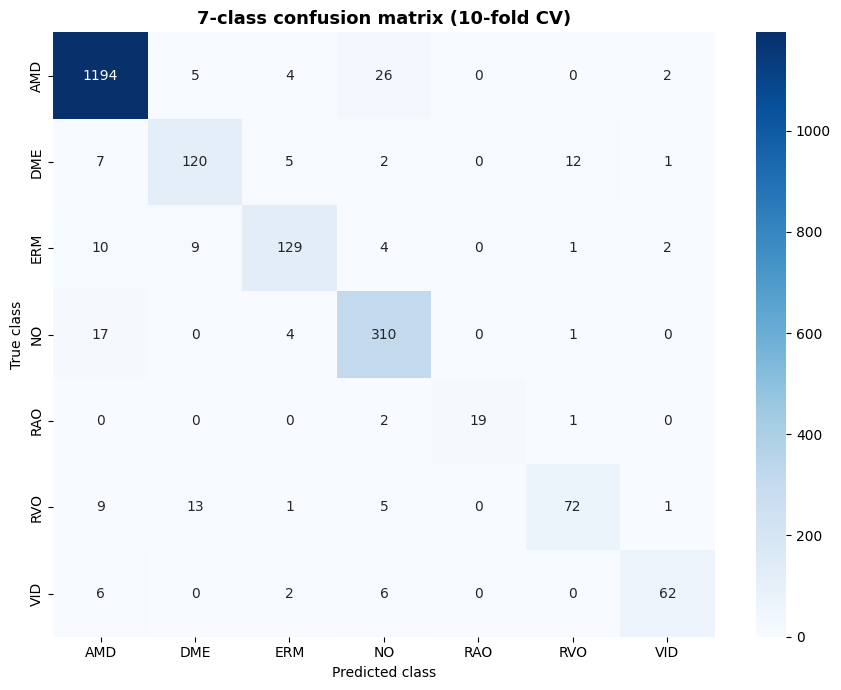

In [55]:
y_pred_7, results_7, oof_dec_7, fold_bundles_7 = leak_free_cv(
    F_list, labels_7, LABEL_NAMES_7, "Case 1: 7-class", "7class", groups, keep_folds=GUI_TEST_FOLDS)
plot_confusion_matrix(labels_7, y_pred_7, LABEL_NAMES_7, "7-class confusion matrix (10-fold CV)",
                      "confusion_matrix_7class.png")

## Cell 14: 10-fold CV - binary model


------------------------------------------------------------
 Case 2: Binary | fold 1/10 (train=1857, test=207)
------------------------------------------------------------
  INCA f1: loaded cache  S=[107, 137, 134]
  fold accuracy = 96.62% | NumPy predictor agrees with scikit-learn on 100.00% of the fold

------------------------------------------------------------
 Case 2: Binary | fold 2/10 (train=1857, test=207)
------------------------------------------------------------
  INCA f2: loaded cache  S=[147, 103, 156]
  fold accuracy = 99.52% | NumPy predictor agrees with scikit-learn on 100.00% of the fold

------------------------------------------------------------
 Case 2: Binary | fold 3/10 (train=1857, test=207)
------------------------------------------------------------
  INCA f3: loaded cache  S=[209, 121, 117]
  fold accuracy = 96.14% | NumPy predictor agrees with scikit-learn on 100.00% of the fold

------------------------------------------------------------
 Case 2: Binar

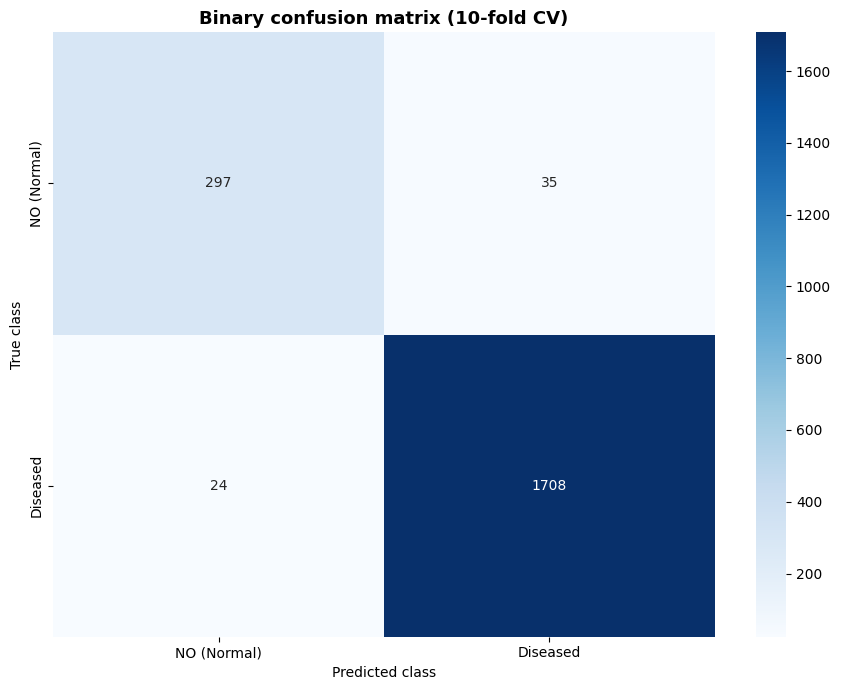

In [56]:
y_pred_2, results_2, oof_dec_2, fold_bundles_2 = leak_free_cv(
    F_list, labels_2, LABEL_NAMES_2, "Case 2: Binary", "binary", groups, keep_folds=GUI_TEST_FOLDS)
plot_confusion_matrix(labels_2, y_pred_2, LABEL_NAMES_2, "Binary confusion matrix (10-fold CV)",
                      "confusion_matrix_binary.png")

## Cell 15: accuracy of both models and difference from the paper

In [57]:
PAPER_F1_7 = {"AMD": 96.98, "DME": 81.11, "ERM": 83.00, "NO": 91.25, "RAO": 81.00, "RVO": 74.46, "VID": 85.29}
PAPER_BINARY = {"Sensitivity": 98.44, "Specificity": 91.86, "Precision": 98.44, "F1-score": 98.44, "Geometric Mean": 95.09}

acc_table = pd.DataFrame([
    {"Model": "7-class", "Your accuracy (%)": results_7["Accuracy"], "Paper (%)": PAPER_ACC["7class"],
     "Notebook reference (%)": REFERENCE_ACC["7class"]},
    {"Model": "Binary (Normal / Diseased)", "Your accuracy (%)": results_2["Accuracy"], "Paper (%)": PAPER_ACC["binary"],
     "Notebook reference (%)": REFERENCE_ACC["binary"]},
])
acc_table["Difference vs paper (%)"] = acc_table["Your accuracy (%)"] - acc_table["Paper (%)"]
acc_table["Difference vs notebook (%)"] = acc_table["Your accuracy (%)"] - acc_table["Notebook reference (%)"]
print("=== OVERALL ACCURACY (10-fold cross-validation) ===")
print(acc_table.round(2).to_string(index=False))

print("\n=== 7-class: per-class F1 vs paper ===")
rows = [{"Class": c, "Your F1 (%)": results_7[c]["F1-score"], "Paper F1 (%)": PAPER_F1_7[c],
         "Difference (%)": results_7[c]["F1-score"] - PAPER_F1_7[c]} for c in CLASS7_NAMES]
print(pd.DataFrame(rows).round(2).to_string(index=False))

print("\n=== Binary (Diseased) vs paper Table 7 ===")
d = results_2["Diseased"]
rows = [{"Metric": m, "Yours (%)": d[m], "Paper (%)": v, "Difference (%)": d[m] - v} for m, v in PAPER_BINARY.items()]
print(pd.DataFrame(rows).round(2).to_string(index=False))

def to_plain(obj):
    return json.loads(json.dumps(obj, default=lambda o: o.item() if hasattr(o, "item") else str(o)))

metrics_out = to_plain({"run": RUN_NAME,
                        "settings": {"CHI2_TOP_K": CHI2_TOP_K, "N_FOLDS": N_FOLDS, "CLASS_WEIGHT": CLASS_WEIGHT,
                                     "USE_FLIP_TTA": USE_FLIP_TTA, "CV_SEED": CV_SEED,
                                     "USE_PATIENT_SPLIT": USE_PATIENT_SPLIT, "RESIZE_MODE": RESIZE_MODE,
                                     "KERNEL_SCALE": KERNEL_SCALE},
                        "paper": {"acc_7class": PAPER_ACC["7class"], "acc_binary": PAPER_ACC["binary"],
                                  "f1_7class": PAPER_F1_7, "binary_diseased": PAPER_BINARY},
                        "7class": results_7, "binary": results_2})
for p in (os.path.join(OUT_DIR, f"results_export_{RUN_NAME}.json"), os.path.join(DEPLOY_DIR, "metrics.json")):
    with open(p, "w") as f:
        json.dump(metrics_out, f, indent=2)
print("\nSaved metrics.json")

=== OVERALL ACCURACY (10-fold cross-validation) ===
                     Model  Your accuracy (%)  Paper (%)  Notebook reference (%)  Difference vs paper (%)  Difference vs notebook (%)
                   7-class              92.34       92.3                   92.34                     0.04                         0.0
Binary (Normal / Diseased)              97.14       97.4                   97.14                    -0.26                         0.0

=== 7-class: per-class F1 vs paper ===
Class  Your F1 (%)  Paper F1 (%)  Difference (%)
  AMD        96.52         96.98           -0.46
  DME        81.63         81.11            0.52
  ERM        86.00         83.00            3.00
   NO        90.25         91.25           -1.00
  RAO        92.68         81.00           11.68
  RVO        76.60         74.46            2.14
  VID        86.11         85.29            0.82

=== Binary (Diseased) vs paper Table 7 ===
        Metric  Yours (%)  Paper (%)  Difference (%)
   Sensitivity   

## Cell 16: calibration - turn SVM scores into percentages
SVM scores are not probabilities. A small logistic-regression calibrator is fitted on the **out-of-fold** SVM decision values
from the cross-validation (so it only learns from predictions made on unseen images). It does **not** change the predicted class;
it only converts the scores into percentages. The report below shows how reliable these percentages are.

In [58]:
def expected_calibration_error(probs, y, n_bins=10):
    conf, pred = probs.max(1), probs.argmax(1)
    correct = (pred == y)
    edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(ece)


def fit_calibrator(oof_dec, y, svm_oof_pred, n_classes, name):
    kind = "sigmoid" if n_classes == 2 else "softmax"
    oof_dec = calibration_features(oof_dec, n_classes)   # binary: decision value; 7-class: decisions + votes
    cv = StratifiedKFold(5, shuffle=True, random_state=CV_SEED)
    best = None
    for C in [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0]:
        P = cross_val_predict(LogisticRegression(C=C, max_iter=5000), oof_dec, y, cv=cv, method="predict_proba")
        ll = log_loss(y, P, labels=list(range(n_classes)))
        if best is None or ll < best[0]:
            best = (ll, C, P)
    ll, C, P = best
    lr = LogisticRegression(C=C, max_iter=5000).fit(oof_dec, y)
    onehot = np.eye(n_classes)[y]
    report = {"best_C": C, "log_loss": float(ll),
              "brier": float(np.mean(np.sum((P - onehot) ** 2, axis=1))),
              "ece": expected_calibration_error(P, y),
              "argmax_accuracy": float(np.mean(P.argmax(1) == y) * 100),
              "svm_accuracy": float(np.mean(svm_oof_pred == y) * 100),
              "agreement_with_svm": float(np.mean(P.argmax(1) == svm_oof_pred) * 100)}
    cal = {"kind": kind, "coef": lr.coef_.astype(np.float64), "intercept": lr.intercept_.astype(np.float64), "C": C}
    print(f"\n{name} calibration (evaluated with 5-fold CV on out-of-fold scores)")
    print(f"  log-loss={report['log_loss']:.4f}  Brier={report['brier']:.4f}  ECE={report['ece']*100:.2f}%")
    print(f"  SVM accuracy={report['svm_accuracy']:.2f}%  | arg-max of percentages gives {report['argmax_accuracy']:.2f}%"
          f"  | same class as SVM in {report['agreement_with_svm']:.2f}% of images")
    return cal, report


cal_7, cal_report_7 = fit_calibrator(oof_dec_7, labels_7, y_pred_7, 7, "7-class")
cal_2, cal_report_2 = fit_calibrator(oof_dec_2, labels_2, y_pred_2, 2, "Binary")


7-class calibration (evaluated with 5-fold CV on out-of-fold scores)
  log-loss=0.2773  Brier=0.1299  ECE=1.71%
  SVM accuracy=92.34%  | arg-max of percentages gives 91.76%  | same class as SVM in 98.30% of images

Binary calibration (evaluated with 5-fold CV on out-of-fold scores)
  log-loss=0.0771  Brier=0.0440  ECE=0.35%
  SVM accuracy=97.14%  | arg-max of percentages gives 97.09%  | same class as SVM in 99.85% of images


## Cell 17: final models on the full dataset
These are the models that go into the GUI. INCA is fitted again on all images (this is the slow part; the result is cached on Drive).
The accuracy of these models is the cross-validation accuracy printed above (a model evaluated on its own training images always looks perfect).

In [59]:
def fit_final(F_list, y, groups, label_names, case_key):
    print(f"\n{'='*60}\n FINAL FIT: {case_key}\n{'='*60}")
    fitted, Fm = fit_inca(F_list, y, groups=groups, tag=" final",
                          key=cache_key(case_key, "final", len(y), groups))
    chi_idx = chi2_feature_selection(Fm, y)
    X = Fm[:, chi_idx]
    model = build_svm(X, y).fit(X, y)
    bundle = make_bundle(case_key, label_names, fitted, chi_idx, model, len(y))
    pred_np, _, _ = bundle_predict(bundle, F_list)
    agree = np.mean(pred_np == model.predict(X)) * 100
    print(f"  S={[b for b, _, _ in fitted]}  Smerge={X.shape[1]}  | training accuracy={accuracy_score(y, pred_np)*100:.2f}% "
          f"(sanity only) | NumPy predictor agrees with scikit-learn on {agree:.2f}% of all images")
    return bundle


bundle_7 = fit_final(F_list, labels_7, groups, LABEL_NAMES_7, "7class")
bundle_2 = fit_final(F_list, labels_2, groups, LABEL_NAMES_2, "binary")


 FINAL FIT: 7class
  INCA final: loaded cache  S=[149, 170, 281]
  S=[149, 170, 281]  Smerge=350  | training accuracy=99.56% (sanity only) | NumPy predictor agrees with scikit-learn on 100.00% of all images

 FINAL FIT: binary
  INCA final: loaded cache  S=[102, 227, 290]
  S=[102, 227, 290]  Smerge=350  | training accuracy=99.71% (sanity only) | NumPy predictor agrees with scikit-learn on 100.00% of all images


## Cell 18: save the pickle files and everything the GUI needs

In [60]:
bundle_7["calibrator"], bundle_7["calibration_report"] = cal_7, cal_report_7
bundle_2["calibrator"], bundle_2["calibration_report"] = cal_2, cal_report_2
bundle_7["metrics"] = to_plain(results_7)
bundle_2["metrics"] = to_plain(results_2)

for name, b in (("retina_7class.pkl", bundle_7), ("retina_binary.pkl", bundle_2)):
    with open(os.path.join(DEPLOY_DIR, name), "wb") as f:
        pickle.dump(b, f, protocol=4)
    print("Saved", name)

# CNN weights (so the GUI works offline and uses exactly the same pretrained weights)
state = {nm: FeatureExtractor(nm).cpu().state_dict() for nm in MODEL_ORDER}
torch.save(state, os.path.join(DEPLOY_DIR, "cnn_weights.pt"))
print("Saved cnn_weights.pt")

info = {"run": RUN_NAME, "n_images": len(image_paths),
        "class_counts": {n: int((labels_7 == i).sum()) for i, n in enumerate(CLASS7_NAMES)},
        "torch": torch.__version__, "S_7class": [d["s"] for d in bundle_7["inca"]],
        "S_binary": [d["s"] for d in bundle_2["inca"]], "Smerge": int(len(bundle_7["chi_idx"])),
        "calibration_7class": cal_report_7, "calibration_binary": cal_report_2}
with open(os.path.join(DEPLOY_DIR, "training_info.json"), "w") as f:
    json.dump(to_plain(info), f, indent=2)

shutil.copy("pbn_core.py", os.path.join(DEPLOY_DIR, "pbn_core.py"))
print(sorted(os.listdir(DEPLOY_DIR)))

Saved retina_7class.pkl
Saved retina_binary.pkl
Saved cnn_weights.pt
['cnn_weights.pt', 'confusion_matrix_7class.png', 'confusion_matrix_binary.png', 'metrics.json', 'pbn_core.py', 'retina_7class.pkl', 'retina_binary.pkl', 'training_info.json']


## Cell 19: test 1 - reload the saved pickle files and compare with scikit-learn
The reloaded bundles must predict exactly like the scikit-learn models for every image.

In [61]:
with open(os.path.join(DEPLOY_DIR, "retina_7class.pkl"), "rb") as f:
    b7 = pickle.load(f)
with open(os.path.join(DEPLOY_DIR, "retina_binary.pkl"), "rb") as f:
    b2 = pickle.load(f)

p7, dec7, _ = bundle_predict(b7, F_list)
p2, dec2, _ = bundle_predict(b2, F_list)
prob7, prob2 = bundle_probabilities(b7, dec7), bundle_probabilities(b2, dec2)
print(f"Reloaded 7-class bundle : training accuracy {np.mean(p7 == labels_7)*100:.2f}%")
print(f"Reloaded binary bundle  : training accuracy {np.mean(p2 == labels_2)*100:.2f}%")
print(f"Probabilities sum to 1  : {np.allclose(prob7.sum(1), 1)} / {np.allclose(prob2.sum(1), 1)}")
print("(training accuracy is only a sanity check; the real accuracy is the cross-validation accuracy above)")

Reloaded 7-class bundle : training accuracy 99.56%
Reloaded binary bundle  : training accuracy 99.71%
Probabilities sum to 1  : True / True
(training accuracy is only a sanity check; the real accuracy is the cross-validation accuracy above)


## Cell 20: test 2 - the GUI code path on unseen images
For the images of a held-out CV fold, features are extracted **live from the image files** (exactly what the GUI does)
and classified with the model of that fold, which never saw those images. The accuracy must match the cached-feature accuracy.

In [62]:
extractors = load_extractors(DEVICE, os.path.join(DEPLOY_DIR, "cnn_weights.pt"))

live = {}
for fold in GUI_TEST_FOLDS:
    for _, te in (fold_bundles_7[fold], fold_bundles_2[fold]):
        for i in te:
            live.setdefault(int(i), None)
for i in tqdm(sorted(live), desc="live feature extraction"):
    live[i] = extract_image_features(load_image(image_paths[i]), extractors, DEVICE, RESIZE_MODE, USE_FLIP_TTA)


def live_features(idx):
    return [np.concatenate([live[int(i)][m] for i in idx]) for m in range(3)]


for fold in GUI_TEST_FOLDS:
    for task, (b, te), y, names in (("7-class", fold_bundles_7[fold], labels_7, LABEL_NAMES_7),
                                    ("Binary", fold_bundles_2[fold], labels_2, LABEL_NAMES_2)):
        Fl, Fc = live_features(te), [F[te] for F in F_list]
        pred_live, _, _ = bundle_predict(b, Fl)
        pred_cached, _, _ = bundle_predict(b, Fc)
        rel = max(float(np.abs(a - c).max() / (np.abs(c).max() + 1e-9)) for a, c in zip(Fl, Fc))
        print(f"\nFold {fold+1} | {task} | {len(te)} unseen images")
        print(f"  accuracy via live GUI pipeline : {np.mean(pred_live == y[te])*100:.2f}%")
        print(f"  accuracy via cached features   : {np.mean(pred_cached == y[te])*100:.2f}%")
        print(f"  same prediction in {np.mean(pred_live == pred_cached)*100:.2f}% of images | "
              f"max relative feature difference {rel:.2e}")
        if task == "7-class":
            for c, n in enumerate(names):
                m = y[te] == c
                if m.any():
                    print(f"    {n:<4} correct: {int(np.sum(pred_live[m] == c))}/{int(m.sum())}")

live feature extraction: 100%|██████████| 390/390 [01:11<00:00,  5.45it/s]



Fold 1 | 7-class | 207 unseen images
  accuracy via live GUI pipeline : 92.27%
  accuracy via cached features   : 92.27%
  same prediction in 100.00% of images | max relative feature difference 0.00e+00
    AMD  correct: 121/124
    DME  correct: 12/14
    ERM  correct: 13/16
    NO   correct: 30/33
    RAO  correct: 2/2
    RVO  correct: 7/10
    VID  correct: 6/8

Fold 1 | Binary | 207 unseen images
  accuracy via live GUI pipeline : 96.62%
  accuracy via cached features   : 96.62%
  same prediction in 100.00% of images | max relative feature difference 0.00e+00


## Cell 21: test 3 - predictions, percentages and Grad-CAM on sample images
This runs the same functions as the GUI. Check that the highlighted area makes sense on the images.

In [ ]:
rng = np.random.default_rng(0)
picks = [int(rng.choice(np.where(labels_7 == c)[0])) for c in (0, 1, 3, 5)]   # AMD, DME, NO, RVO samples

fig, axes = plt.subplots(len(picks), 3, figsize=(13, 3.6 * len(picks)))
for r, i in enumerate(picks):
    img = load_image(image_paths[i])
    out = predict_from_features(b7, b2, extract_image_features(img, extractors, DEVICE, RESIZE_MODE, USE_FLIP_TTA))
    c7 = int(out["pred7"][0])
    p7_, p2_ = out["probs7"][0], out["probs2"][0]
    cam = gradcam(img, extractors, b7, c7, DEVICE, RESIZE_MODE, USE_FLIP_TTA)["combined"]
    region = describe_region(cam, 0.6)
    print(f"{os.path.basename(image_paths[i])}: true={CLASS7_NAMES[labels_7[i]]} | 7-class={CLASS7_NAMES[c7]} "
          f"({p7_[c7]*100:.1f}%) | binary={CLASS2_NAMES[int(out['pred2'][0])]} (Diseased {p2_[1]*100:.1f}%) | {region['text']}")
    axes[r, 0].imshow(img); axes[r, 0].set_title(f"True: {CLASS7_NAMES[labels_7[i]]}")
    axes[r, 1].imshow(overlay_heatmap(img, cam)); axes[r, 1].set_title(f"Grad-CAM for {CLASS7_NAMES[c7]} ({p7_[c7]*100:.1f}%)")
    axes[r, 2].imshow(img)
    axes[r, 2].contour(resize_cam(cam, img.size), levels=[0.6], colors="lime", linewidths=1.5)
    axes[r, 2].set_title("Region with strongest evidence")
    for a in axes[r]:
        a.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(DEPLOY_DIR, "sample_gradcam.png"), dpi=130)
plt.show()

## Cell 22: zip everything and download

In [ ]:
from google.colab import files
zip_path = shutil.make_archive("/content/deployment", "zip", DEPLOY_DIR)
print(zip_path, f"{os.path.getsize(zip_path) / 1e6:.0f} MB")
print(sorted(os.listdir(DEPLOY_DIR)))
files.download(zip_path)